# Tokenizing text

In [3]:
# reading a short story as text sample
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
print("Total number of characters: ", len(raw_text))
print(raw_text[:99])

Total number of characters:  20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


In [4]:
# splitting the text using the re (regular expression) library at whitespace character
import re
text = "Hello, world. This, is a test."
result = re.split(r'(\s)', text)
print(result)

# splitting on whitespaces (\s), commas and periods ([,.])
result = re.split(r'([,.]|\s)', text)
print(result)

# we can remove the white space characters
result = [i for i in result if i.strip()] # strip() removes all leading/trailing whitespaces from a string
print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']
['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']
['Hello', ',', 'world', '.', 'This', ',', 'is', 'a', 'test', '.']


In [5]:
# adding more properties to our tokenizer
text = "Hello, world. Is this-- a test?"
result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [i for i in result if i.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [6]:
# implementing our basic tokenizer on the-verdict
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [i.strip() for i in preprocessed if i.strip()]
print(len(preprocessed))
print(preprocessed[:30])

4690
['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


# Converting tokens into token IDs

We convert these tokens from python string to an integer representation. We first need a vocabulary which will define how each unique token (word/special character) maps to a unique integer. We basically prepare a one-to-one correspondence between each unique token and a unique token id.

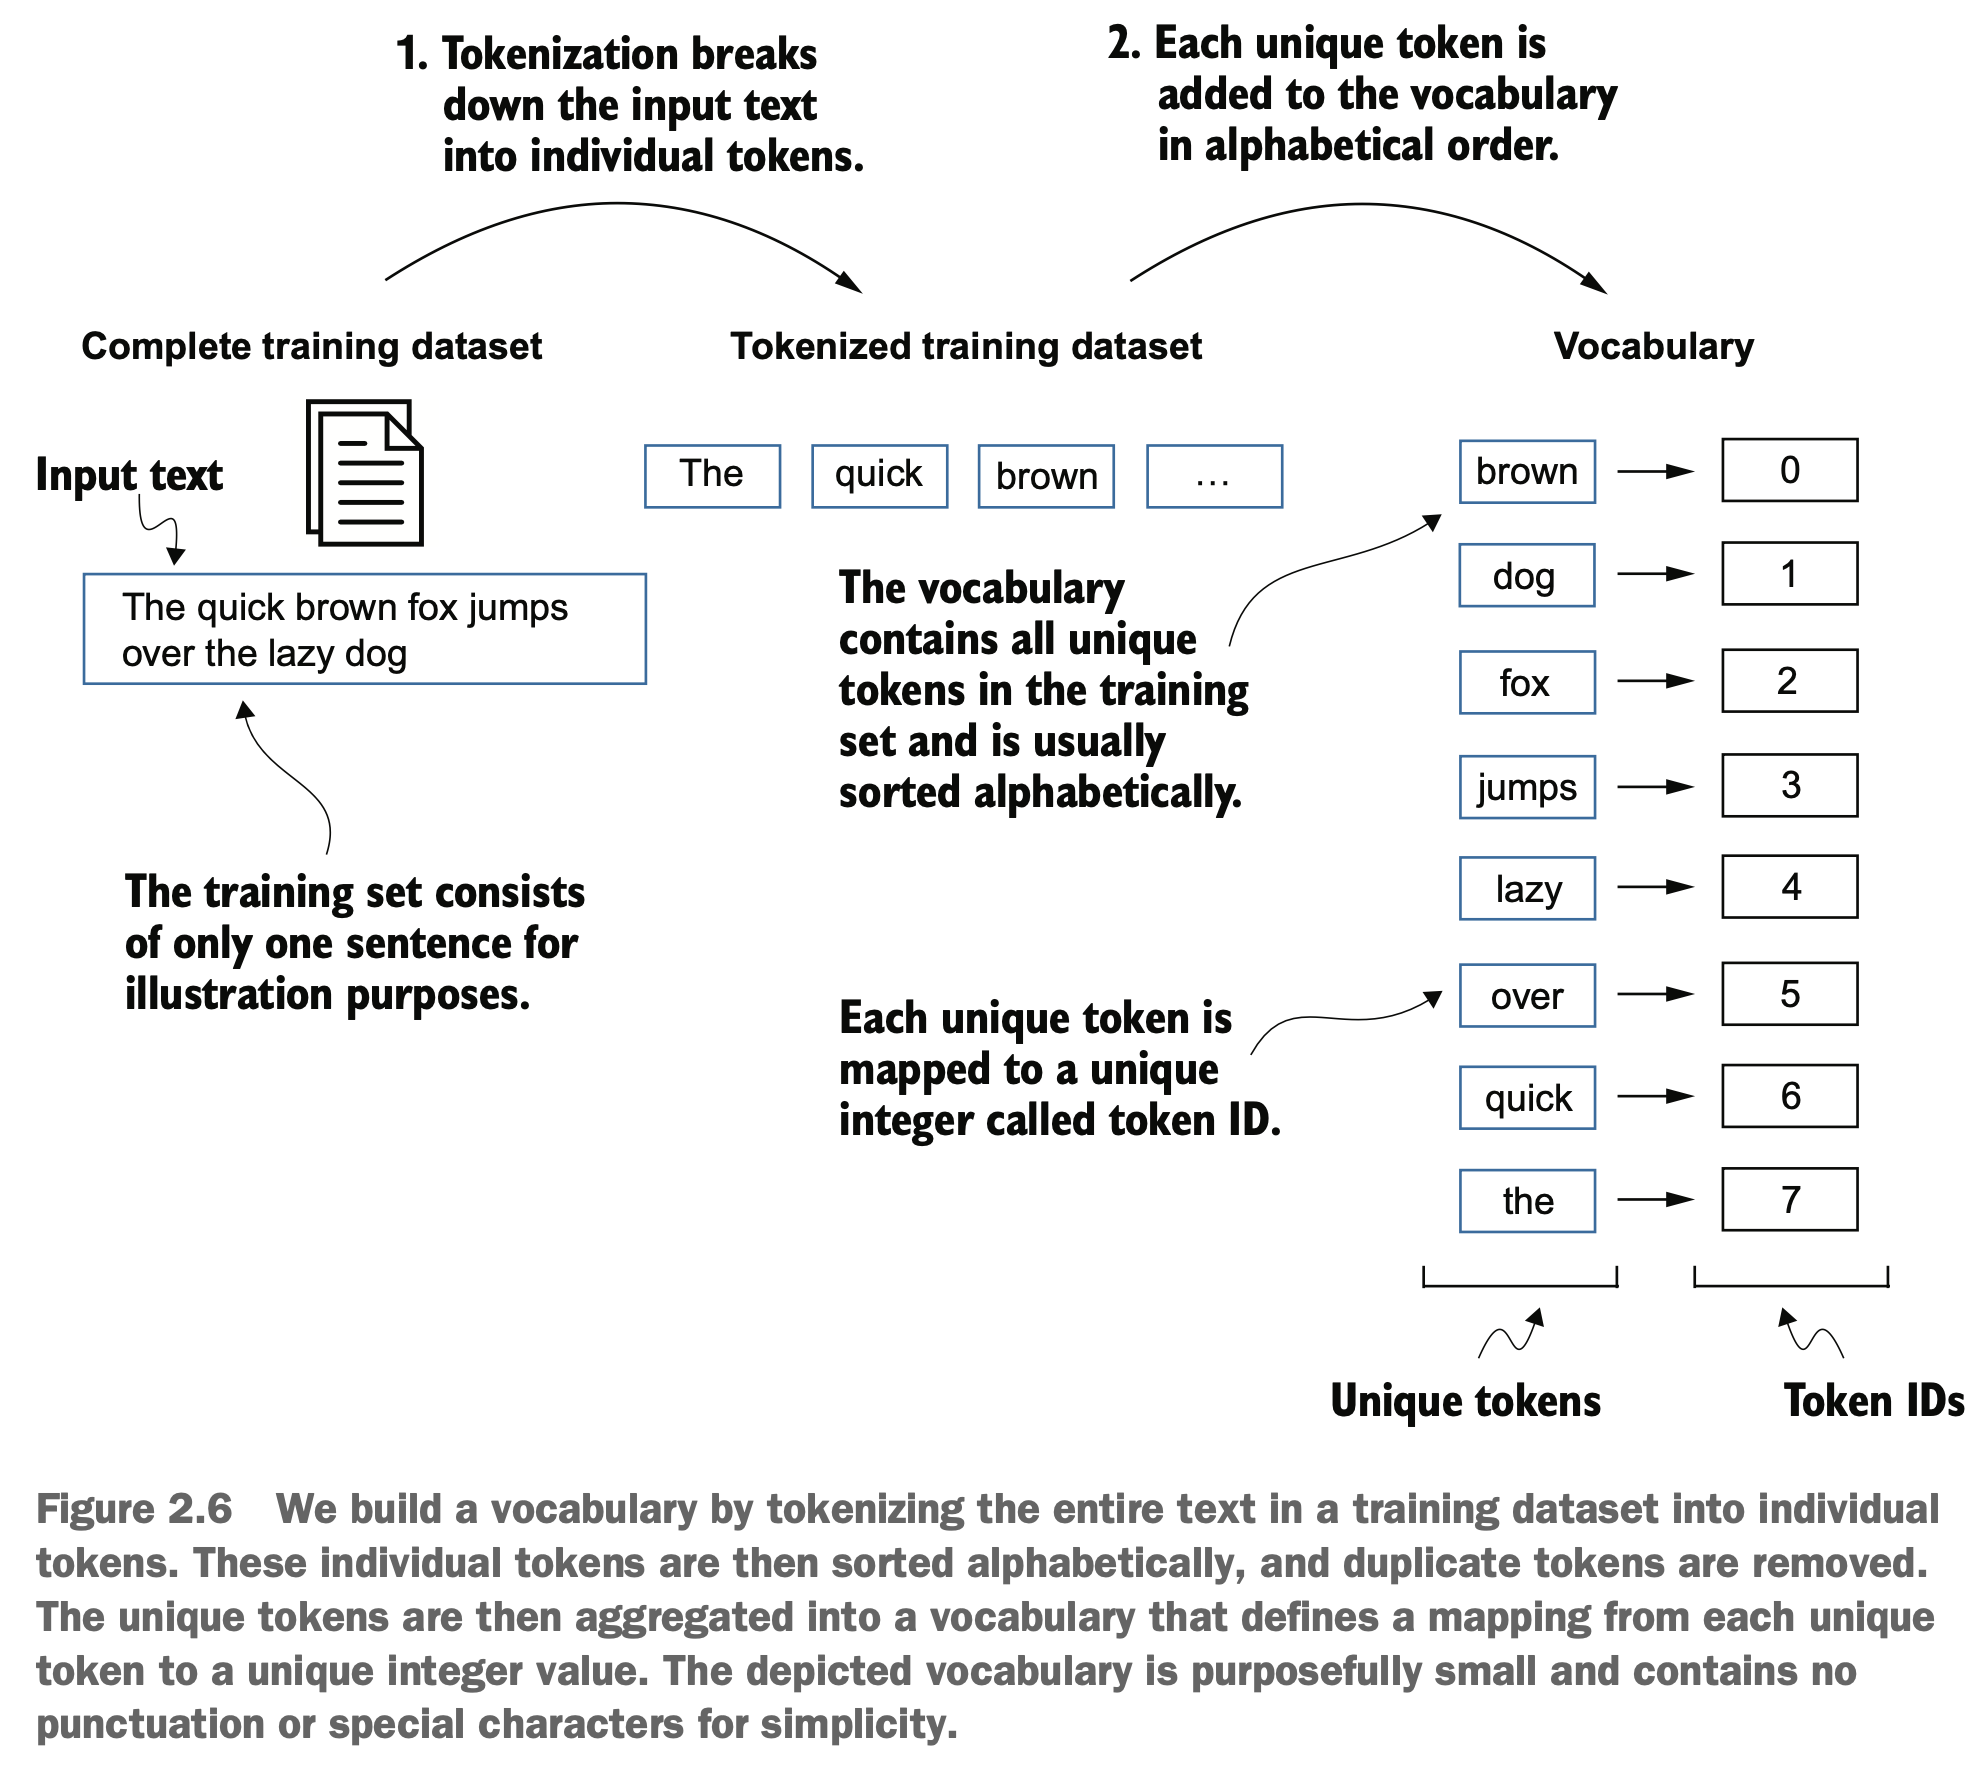

In [13]:
# create a list of unique tokens and sort them alphabetically
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)
print(all_words)
print(vocab_size)

['!', '"', "'", '(', ')', ',', '--', '.', ':', ';', '?', 'A', 'Ah', 'Among', 'And', 'Are', 'Arrt', 'As', 'At', 'Be', 'Begin', 'Burlington', 'But', 'By', 'Carlo', 'Chicago', 'Claude', 'Come', 'Croft', 'Destroyed', 'Devonshire', 'Don', 'Dubarry', 'Emperors', 'Florence', 'For', 'Gallery', 'Gideon', 'Gisburn', 'Gisburns', 'Grafton', 'Greek', 'Grindle', 'Grindles', 'HAD', 'Had', 'Hang', 'Has', 'He', 'Her', 'Hermia', 'His', 'How', 'I', 'If', 'In', 'It', 'Jack', 'Jove', 'Just', 'Lord', 'Made', 'Miss', 'Money', 'Monte', 'Moon-dancers', 'Mr', 'Mrs', 'My', 'Never', 'No', 'Now', 'Nutley', 'Of', 'Oh', 'On', 'Once', 'Only', 'Or', 'Perhaps', 'Poor', 'Professional', 'Renaissance', 'Rickham', 'Riviera', 'Rome', 'Russian', 'Sevres', 'She', 'Stroud', 'Strouds', 'Suddenly', 'That', 'The', 'Then', 'There', 'They', 'This', 'Those', 'Though', 'Thwing', 'Thwings', 'To', 'Usually', 'Venetian', 'Victor', 'Was', 'We', 'Well', 'What', 'When', 'Why', 'Yes', 'You', '_', 'a', 'abdication', 'able', 'about', 'above',

In [22]:
# now we create a vocabulary, which is a dictionary containing each unique token and its corresponding id
vocab = {token:integer for integer, token in enumerate(all_words)}
for index, word in enumerate(vocab.items()):
    print(word)
    if index == 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [23]:
# implementing a simple text tokenizer
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s, i in vocab.items()}
    
    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [27]:
# using the tokenizer
tokenizer = SimpleTokenizerV1(vocab)

# turning text to ids
text = """"It's the last he painted, you know,"Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

# turning ids to text
print(tokenizer.decode(ids))

# testing the tokenizer on a random string
text = "Hello, do you like tea?"
try:
    print(tokenizer.encode(text))
except:
    print("Word not present in vocabulary.")

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]
" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.
Word not present in vocabulary.


In the above example, "Hello" isn't present in our vocabulary, thus the tokenizer fails. This shows the importance of a vast and diverse training set to build a vocabulary that contains various possible words in the language.

# Adding special context tokens
Now we enhance our tokenizer to handle new words not present in the vocabulary and to seprate two different text sources.

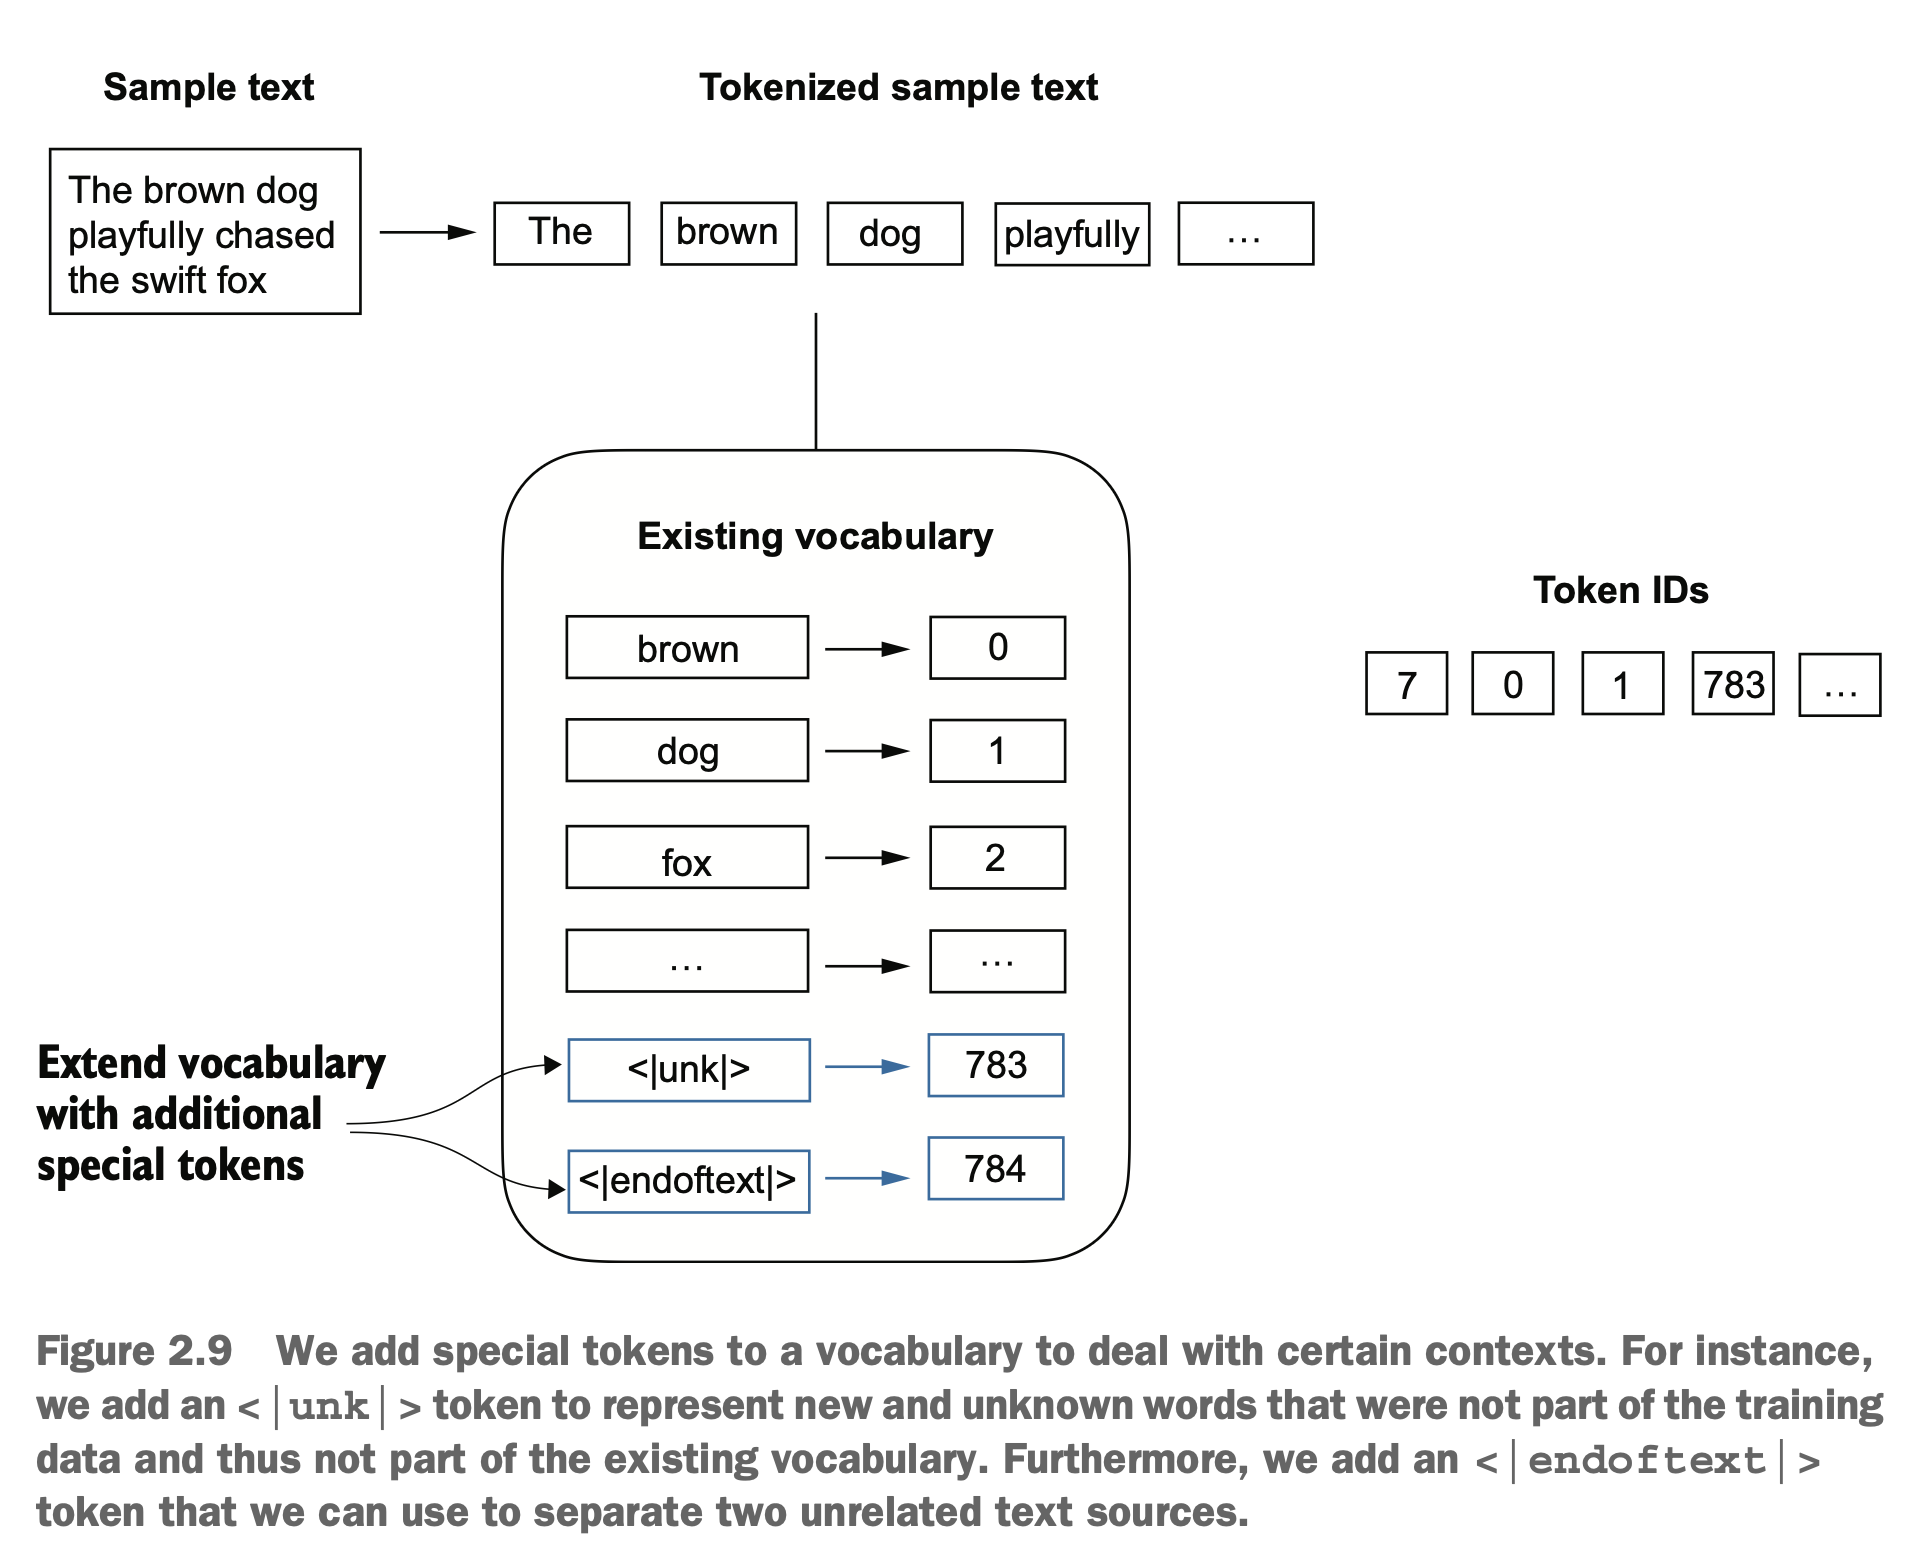

In [32]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token:integer for integer, token in enumerate(all_tokens)}
print(len(vocab.items()))

# printing the last 5 elements of the new vocabulary
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

1132
('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [35]:
# updated tokenizer to handle unknown words
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s, i in vocab.items()}
    
    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text

In [37]:
# testing the new tokenizer
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text = " <|endoftext|> ".join((text1, text2))
print(text)

tokenizer = SimpleTokenizerV2(vocab)
print(tokenizer.encode(text))
print(tokenizer.decode(tokenizer.encode(text)))

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.
[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]
<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


We have other types of special tokens like:
1. [BOS] (beginning of sequence): marks the start of a text
2. [EOS] (end of sequence): similar to <|endoftext|>, which marks the end of a text
3. [PAD] (padding): when training in batches, the strings could be of different lengths, so we make their lengths equal by adding padding.

In practice, we use masks to avoid attending to padded tokens and actual GPT like models don't use a simplistic tokenizer, but use a more complicated method of tokenizing called BPE (byte-pair encoding).

# Byte pair encoding
It is a more sophisticated tokenizing method which is based on words/subwords/special characters etc. We will use a python library called tiktoken to implement BPE efficiently.

In [38]:
from importlib.metadata import version
import tiktoken
print("tiktoken version: ", version("tiktoken"))

tiktoken version:  0.14.0


In [39]:
# using the tiktoken module for bpe
tokenizer = tiktoken.get_encoding("gpt2")
text = (
"Hello, do you like tea? <|endoftext|> In the sunlit terraces"
"of someunknownPlace."
)
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


In [40]:
string = tokenizer.decode(integers)
print(string)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


The BPE tokenizer here handles unknown words better than our SimpletokenizerV2 because unlike our treatment, where each word was one token, BPE breaks down unknown words down to subwords or individual characters. BPE builds its vocabulary by merging frequent characters into subwords and frequent subwords into words.

In [52]:
extext = ("Akwirw ier")
exintegers = tokenizer.encode(extext, allowed_special={"<|endoftext|>"})

# printing individual token id
for i in exintegers:
    print(i)

# printing token associated with each id
for i in exintegers:
    print(tokenizer.decode([i]))

# reconstructing the original string
print(tokenizer.decode(exintegers))


33901
86
343
86
220
959
Ak
w
ir
w
 
ier
Akwirw ier


# Data sampling with sliding window
The next step in creating the embeddings for LLM is to generate input-output pairs for training. The LLMs are pre-trained by predicting the next word in a text. We build the data loader that get the input-output pair using a sliding window.

In [57]:
# tokenizing the story using BPE
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

# removing the first 50 tokens
enc_sample = enc_text[50:]

5145


Our target is next word prediction, so the input x would be a word and target (output) would be the next word following x, which we will denote as y. So, x will be words from say 0 to 100 and y would be the words 1 to 101. Now to create the input-output pairs, we create x which will have input tokens and y will have the targets, which will be inputs shifted by 1.

In [58]:
# defining the next word prediction mechanism
context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}", f" y: {y}")

x: [290, 4920, 2241, 287]  y: [4920, 2241, 287, 257]


In [59]:
# processing the inputs with targets, we create the next-word prediction task
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


The above code shows us the task that the LLM needs to learn. The ids on the left is fed into the LLM and it should predict the id on the right at each step. Now we convert the ids into text for a better understanding.

In [62]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


Now we want a data-loader that can iterate over the input dataset and returns the inputs and targets as pytorch tensors.

In [63]:
# implementing the dataset
import torch
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt)
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i+max_length]
            target_chunk = token_ids[i+1:i+max_length+1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    
    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, index):
        return self.input_ids[index], self.target_ids[index]

In [64]:
# implementing the data loader
def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )
    return dataloader

In [65]:
# testing the dataloader
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=1, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [66]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


If we look at the first and second batch, we see that both the input and output tensors differ by 1 in both the batches. How many steps are taken between two consecutive batches is dictated by the stride. Here we have used a stride of 1, thus, two consecutive batches differ by 1.

In [74]:
# testing dataloader with different context size and strides
ex1dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=2, stride=2, shuffle=False)
ex1data_iter = iter(ex1dataloader)
ex1first_batch = next(ex1data_iter)
ex1second_batch = next(ex1data_iter)
print(ex1first_batch)
print(ex1second_batch)

[tensor([[ 40, 367]]), tensor([[ 367, 2885]])]
[tensor([[2885, 1464]]), tensor([[1464, 1807]])]


In [75]:
ex2dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=8, stride=2, shuffle=False)
ex2data_iter = iter(ex2dataloader)
ex2first_batch = next(ex2data_iter)
ex2second_batch = next(ex2data_iter)
print(ex2first_batch)
print(ex2second_batch)

[tensor([[  40,  367, 2885, 1464, 1807, 3619,  402,  271]]), tensor([[  367,  2885,  1464,  1807,  3619,   402,   271, 10899]])]
[tensor([[ 2885,  1464,  1807,  3619,   402,   271, 10899,  2138]]), tensor([[ 1464,  1807,  3619,   402,   271, 10899,  2138,   257]])]


# Creating token embeddings
Now we see how can we convert the ids into embedding vectors. These are important because a token id doesn't carry semantic or contextual information of the token, thus, to train a NN, we convert it into a vector embedding that carries the information about the token.

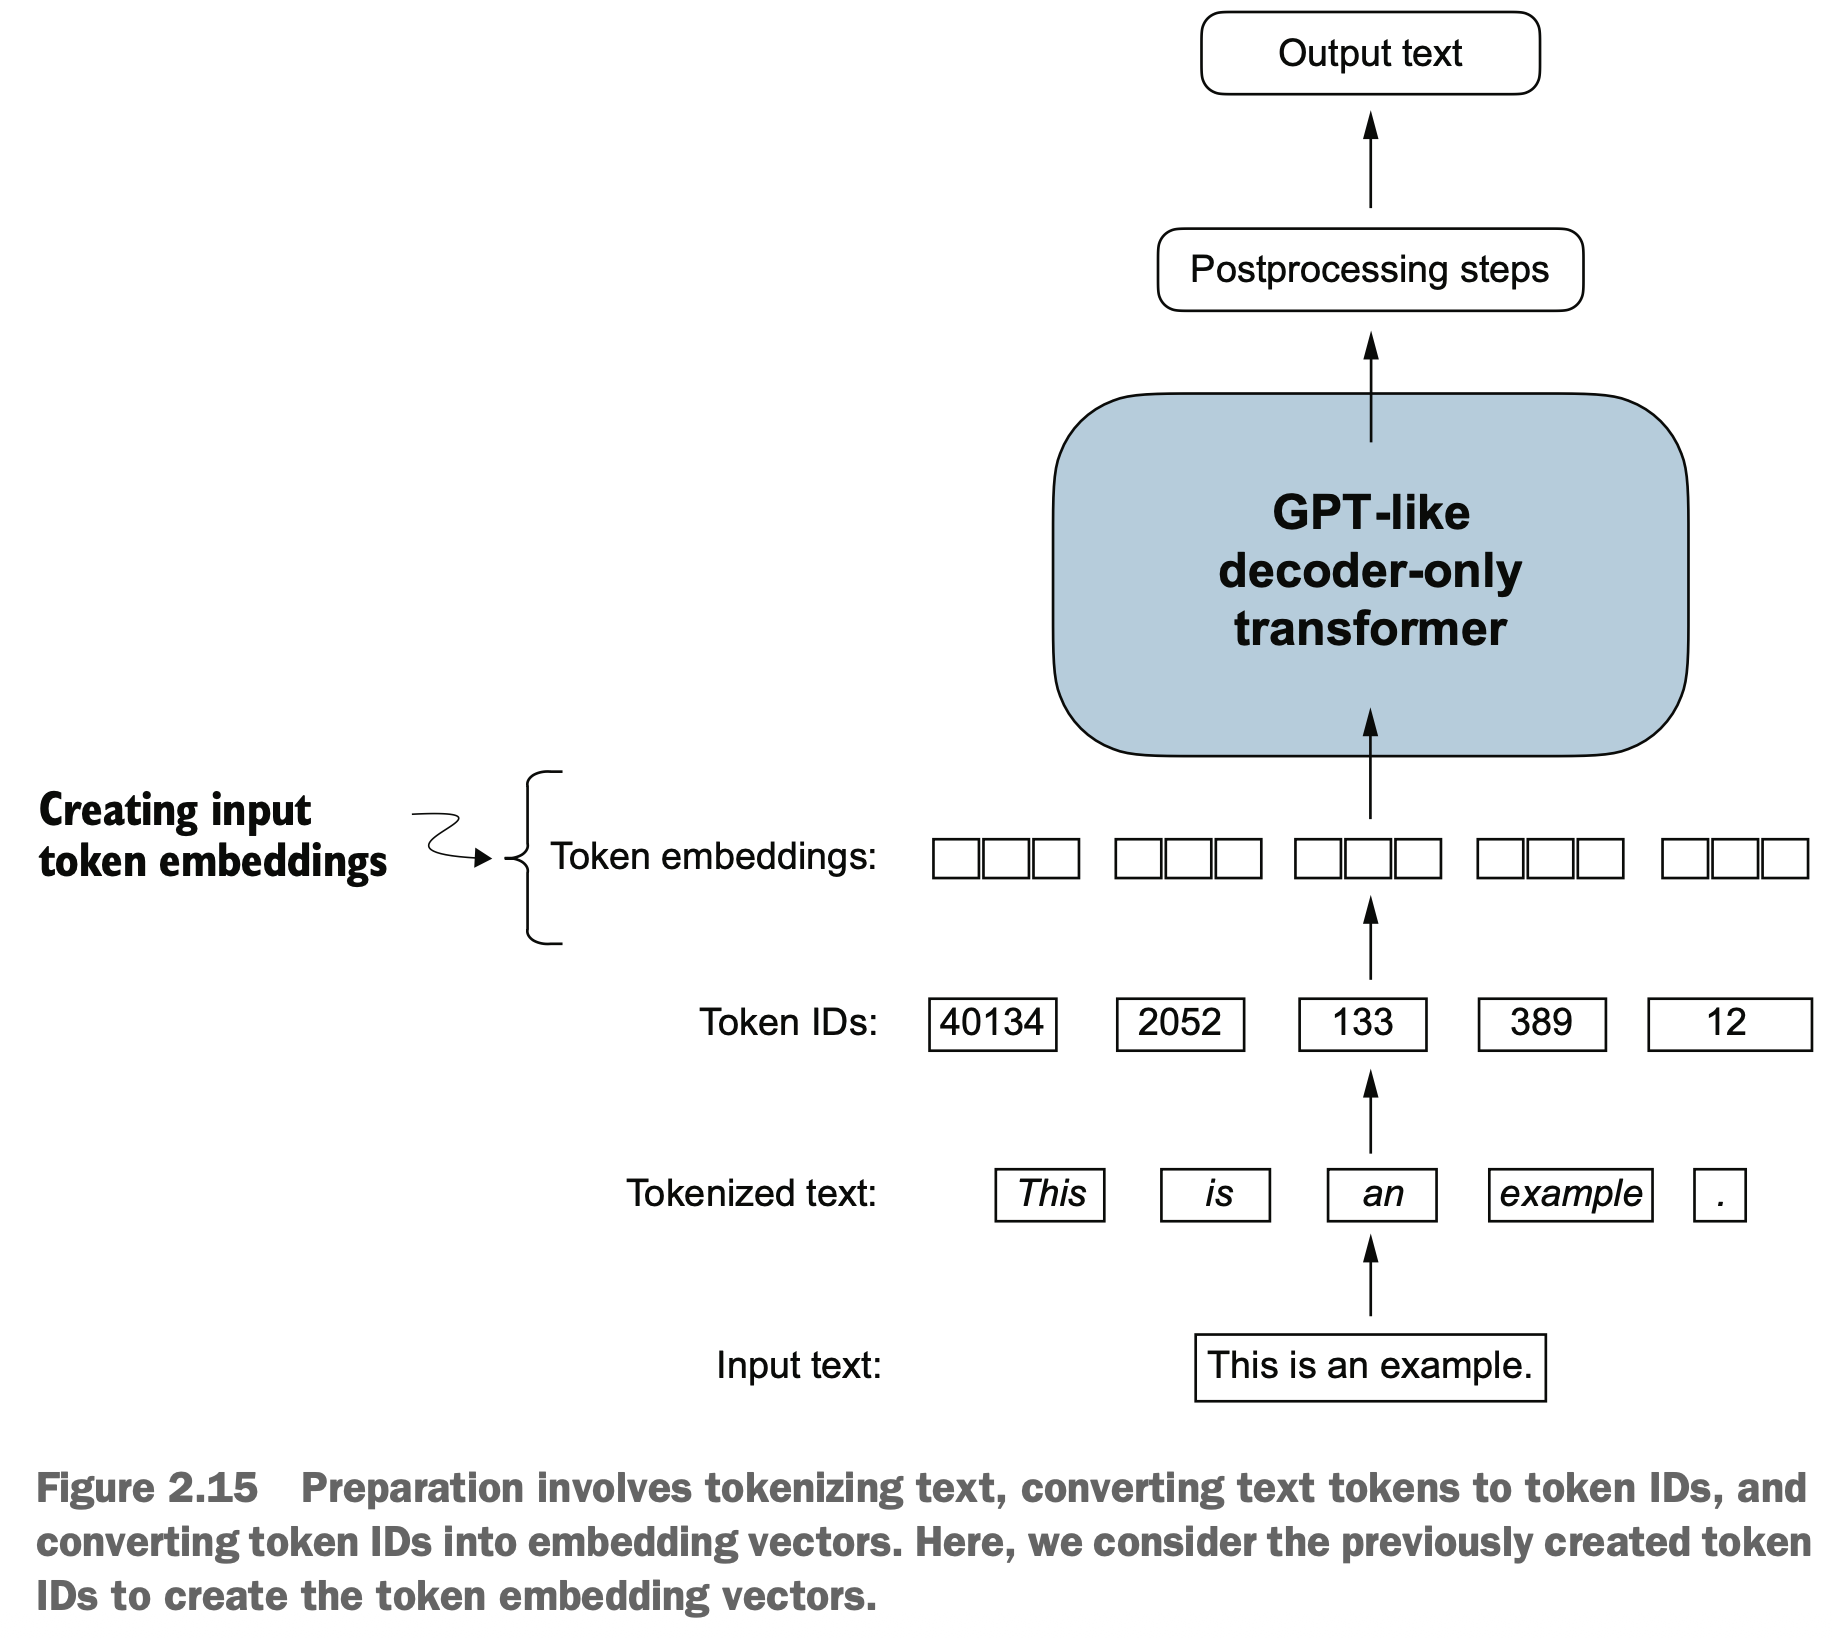

In [76]:
# example showing how to get embedding vector from token IDs
input_ids = torch.tensor([2,3,5,1])
vocab_size = 6
output_dim = 3
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


In [77]:
# we get the weights for one of the token ids
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [78]:
# converting all the token ids into a vector embedding
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


Now that we have the embeddings, we need to inject the positional information into the embeddings as well. Right now, each vector only represents one token without the information about its position in the text, thus, we try to inject more contextual information into the embeddings so that they represent the token as well as the position of the token in the text.

# Encoding word positions
The self-attention mechanism of LLMs do not have a notion of position or the order in which tokens are presented in a sequence. Thus, each token gets the same embedding no matter where it appears in the text, thus, leaving out the information about the position of the token. To insert the positional information into the embeddings, we have two options for position-aware embeddings:
1. relative positional embeddings: the emphasis is on the relative position or distance between tokens. The model learns how far apart a particular token appears in relation to another. This is better as the model can generalize better to sequences of varying length even if texts of that length didn't appear in training.
2. absolute positional embeddings: each position has a particular embedding, thus, it doesn't take into account the relative position of other tokens. The model learns at which exact position a particular token appears.

Each positional embedding have unique values which abstracts the information about the position at which a particular token appears.

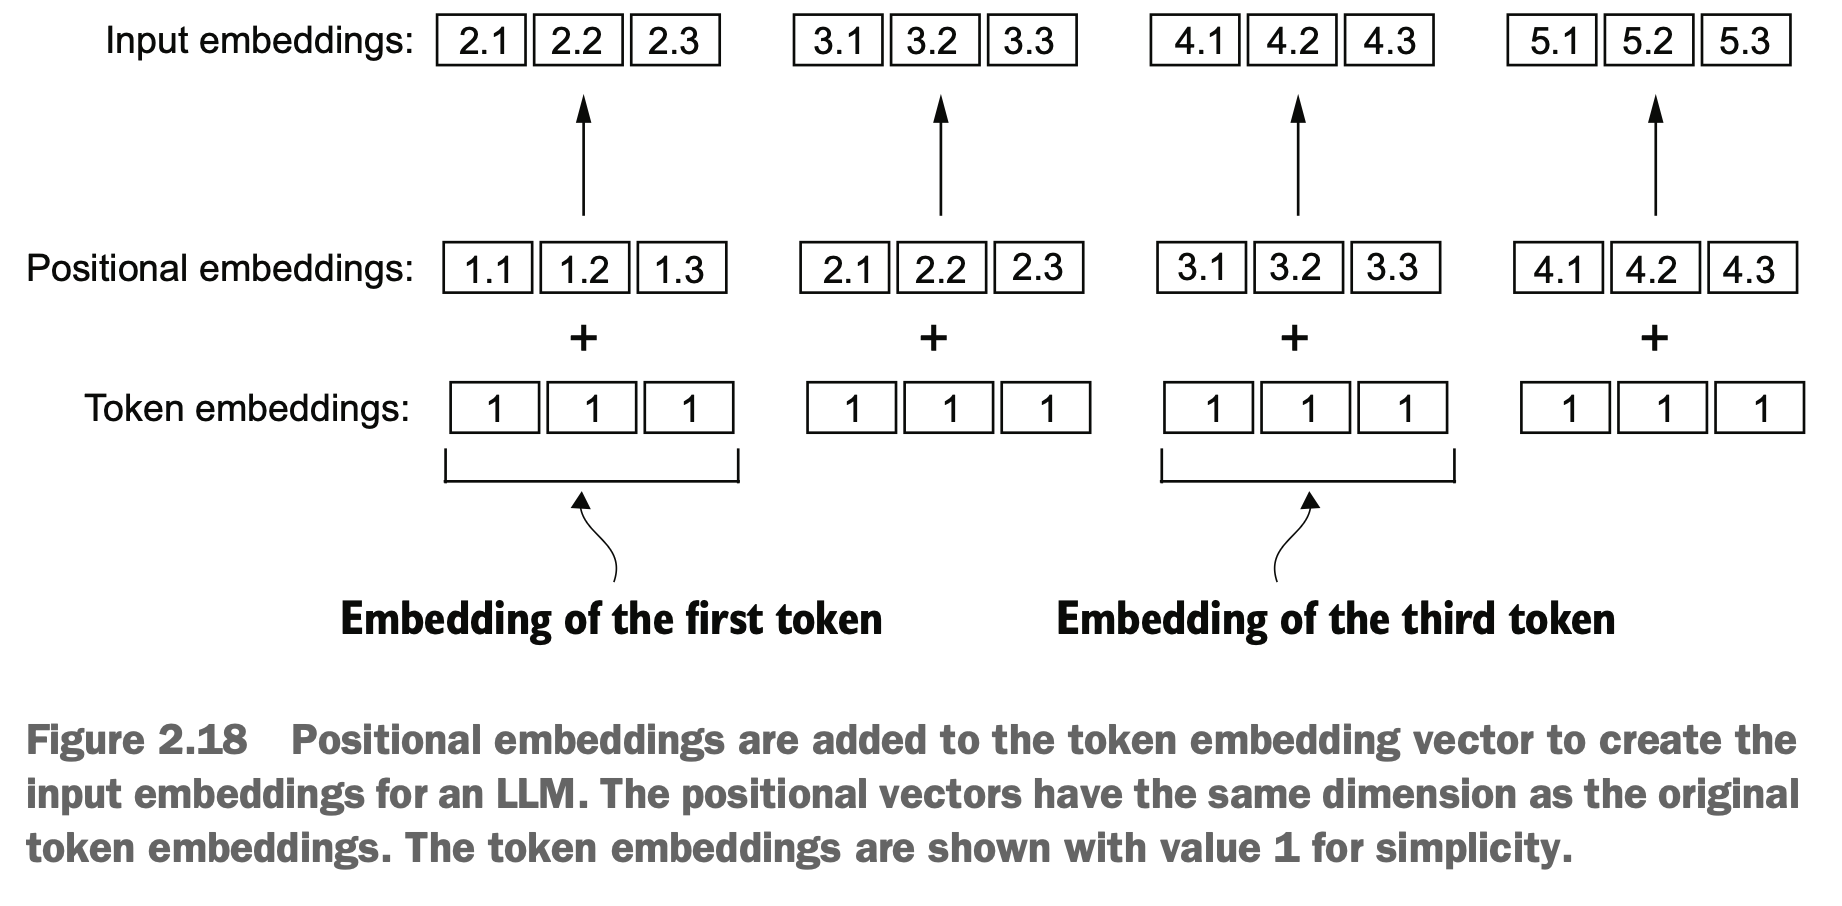

Now we try a realistic example where our embedding dimension if 256 with a vocab size of 50257.

In [79]:
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

# instantiating the data loader
max_length = 4
dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=max_length, stride=max_length, shuffle=False)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Token IDs:\n", inputs)
print("\nInputs shape: \n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape: 
 torch.Size([8, 4])


In [81]:
# now embed these tokens into 256-dimensional vectors
token_embedding = token_embedding_layer(inputs)
print(token_embedding.shape)

# now we create an absolute positional embedding
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([8, 4, 256])
torch.Size([4, 256])


In [82]:
# now we add the positional embeddings into the token embeddings
input_embeddings = token_embedding + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


The above input embeddings has the information about the tokens as well as their position in the text.

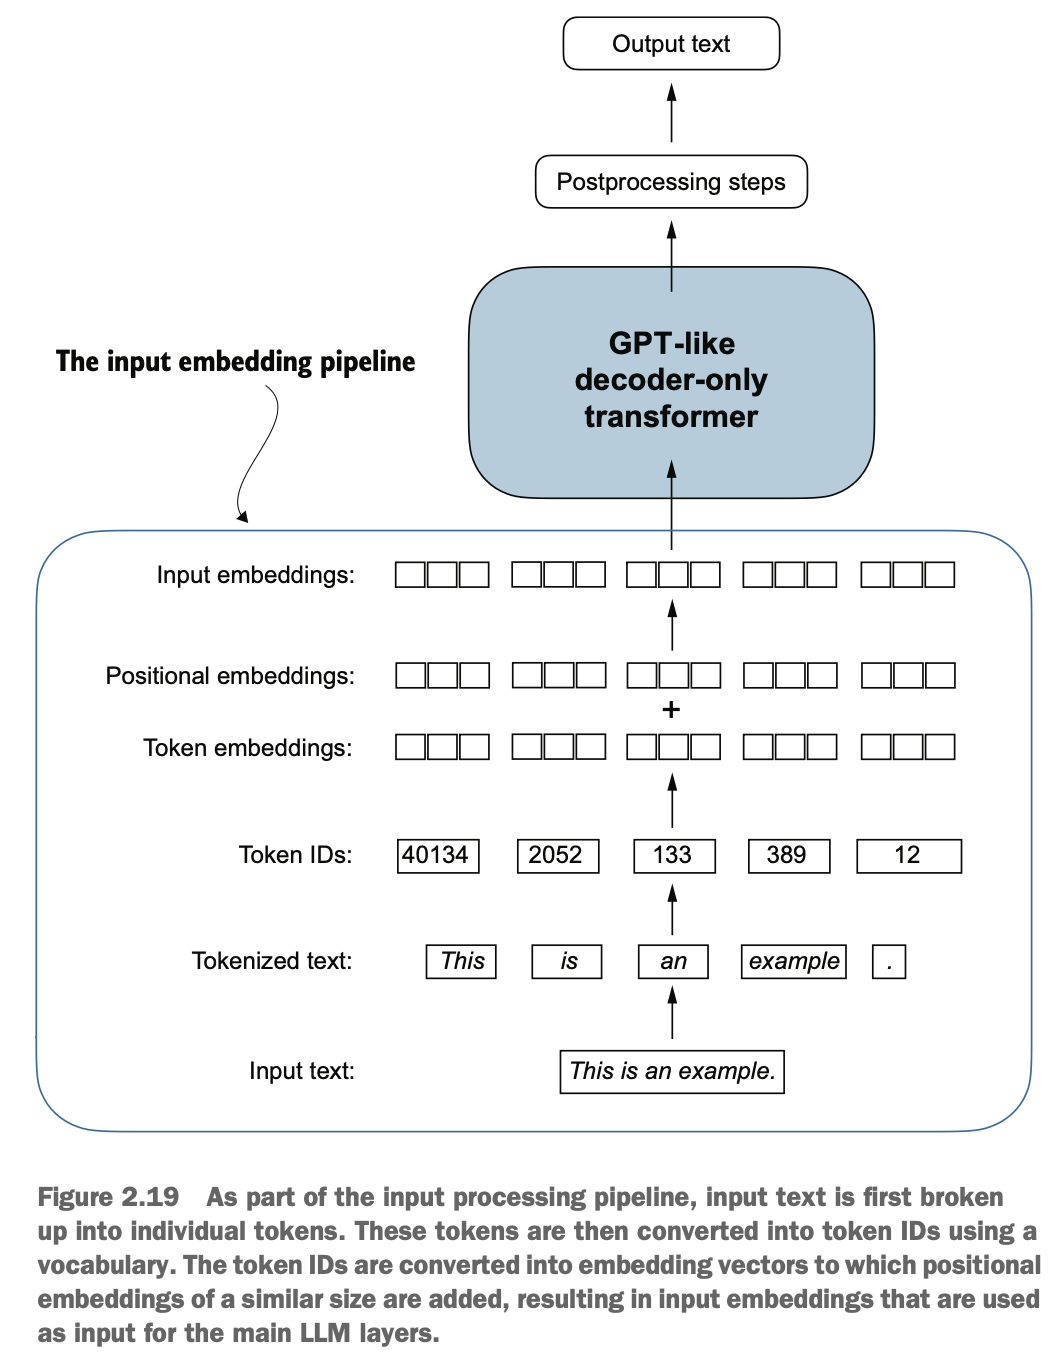